# 03 · Segmentación: ablaciones, robustez, calibración, incertidumbre, explicabilidad y eficiencia

**Entradas** (generadas por `scripts/seg_experiments.py`):

* `seg_ablations.csv`: factores × niveles × ≥ 3 semillas, evaluados en **validación**.
* `seg_robustness.csv`: perturbaciones con severidad 0–5 y TTA, en test.
* `seg_loco.csv`: *leave-one-cell-type-out*.
* `models/seg/*.keras`: el modelo base, usado para calibración, incertidumbre y Grad-CAM.

Si faltan, cada sección lo indica. La robustez del baseline clásico se calcula siempre, sobre datos
sintéticos en modo demo, para validar el código.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from project.config import CFG, set_global_seed
from project.reporting import degradation_auc
from project.stats import bootstrap_ci, fmt_ci

warnings.filterwarnings("ignore", category=RuntimeWarning)
set_global_seed(CFG.seed)
ROOT = Path("..").resolve(); TAB = ROOT / "reports/tables"
from project.config import report_dirs
_, FIG = report_dirs(ROOT, (TAB / "seg_robustness.csv").exists())
try:
    import tensorflow  # noqa: F401
    HAS_TF = True
except ImportError:
    HAS_TF = False
MODELS = sorted((ROOT / "models/seg").glob("unetpp_base_f100_s*.weights.h5")) if (ROOT / "models/seg").exists() else []
print("TensorFlow:", HAS_TF, "| modelos base:", [m.name for m in MODELS])

TensorFlow: True | modelos base: ['unetpp_base_f100_s0.weights.h5']


## 1. Ablaciones (≥ 3 semillas)

Factores: resolución, augmentation, pérdida, preentrenamiento y normalización. El análisis usa un modelo
mixto `ap ~ C(nivel)` con intercepto aleatorio por imagen, dentro de cada factor. Así se respeta el
diseño de medidas repetidas (mismas imágenes de validación para todas las variantes y semillas). Como
complemento se aplica Friedman + Holm sobre las medias por imagen.

In [2]:
AB = TAB / "seg_ablations.csv"
if AB.exists():
    from project.reporting import pairwise_report
    ab = pd.read_csv(AB)
    for factor, g in ab.groupby("factor"):
        g = g.assign(modelo=g.nivel)
        print(f"\n=== {factor} ===")
        print(g.groupby("nivel").ap.agg(["mean", "std"]).round(4))
        rep = pairwise_report(g, "ap", delta=0.02)
        print(rep["pairwise"][["A", "B", "mean_diff", "p_holm", "cliffs_delta", "practically_relevant"]].round(4))
        try:
            import statsmodels.formula.api as smf
            fit = smf.mixedlm("ap ~ C(nivel)", g.groupby(["nivel", "id_imagen"], as_index=False).ap.mean(),
                              groups=g.groupby(["nivel", "id_imagen"], as_index=False).ap.mean().id_imagen).fit()
            print(fit.summary().tables[1].round(4))
        except Exception as e:
            print('modelo mixto no disponible:', type(e).__name__, e)
    # Interacción resolución × normalización (si se corrió el diseño factorial completo)
else:
    print("Pendiente: `python scripts/seg_experiments.py ablations --seeds 0 1 2`.")


=== augment ===
                      mean     std
nivel                             
geom+photo+elastic  0.1923  0.1395
none                0.1764  0.1278
                    A     B  mean_diff  p_holm  cliffs_delta  \
0  geom+photo+elastic  none     0.0159  0.1411        0.0522   

   practically_relevant  
0                 False  


                   Coef. Std.Err.       z  P>|z|  [0.025  0.975]
Intercept          0.192    0.015  13.174  0.000   0.164   0.221
C(nivel)[T.none]  -0.016    0.005  -3.107  0.002  -0.026  -0.006
Group Var          0.017    0.115                               

=== encoder ===
                     mean     std
nivel                            
resnet50_imagenet  0.2078  0.1411
scratch            0.1923  0.1395
                   A        B  mean_diff  p_holm  cliffs_delta  \
0  resnet50_imagenet  scratch     0.0155     0.0        0.0723   

   practically_relevant  
0                 False  
                      Coef. Std.Err.       z  P>|z|  [0.025  0.975]
Intercept             0.208    0.015  13.575  0.000   0.178   0.238
C(nivel)[T.scratch]  -0.015    0.004  -4.353  0.000  -0.022  -0.009
Group Var             0.019    0.185                               

=== loss ===
            mean     std
nivel                   
bce       0.1662  0.1262
bce_dice  0.1923  0.1395


     A         B  mean_diff  p_holm  cliffs_delta  practically_relevant
0  bce  bce_dice    -0.0261     0.0       -0.1026                  True
                      Coef. Std.Err.       z  P>|z| [0.025 0.975]
Intercept             0.166    0.015  11.452  0.000  0.138  0.195
C(nivel)[T.bce_dice]  0.026    0.004   6.152  0.000  0.018  0.034
Group Var             0.017    0.138                             


## 2. Robustez ante perturbaciones (curvas de degradación) y TTA

,modelo,perturbacion,auc_relativa,caida_sev5
0,U-Net++ + Watershed,blur,0.651,0.912
1,U-Net++ + Watershed,brightness,1.011,0.002
2,U-Net++ + Watershed,contrast,1.015,-0.011
3,U-Net++ + Watershed,illumination,0.974,0.117
4,U-Net++ + Watershed,jpeg,0.878,0.490
5,U-Net++ + Watershed,noise,0.878,0.446


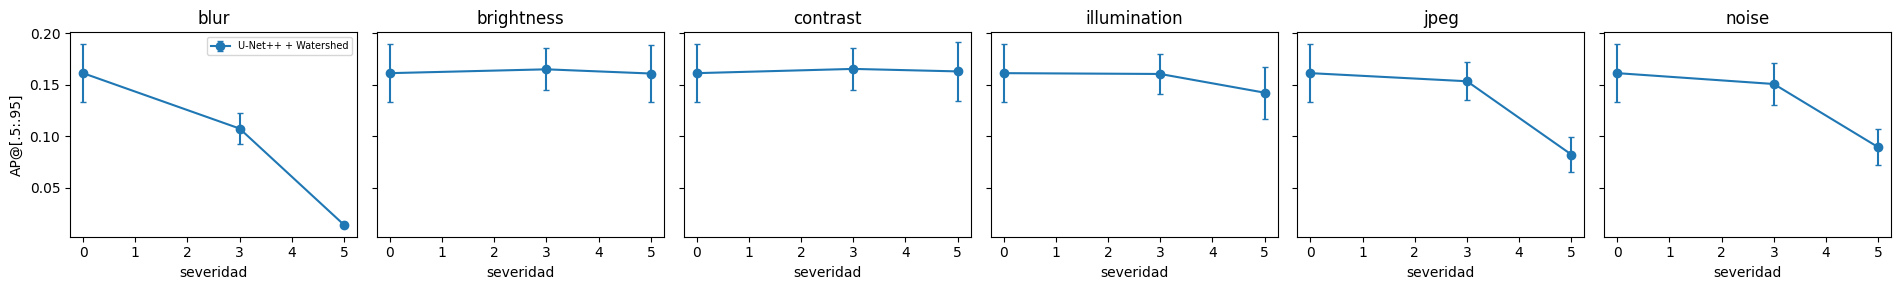

In [3]:
RB = TAB / "seg_robustness.csv"
if RB.exists():
    rb = pd.read_csv(RB)
else:
    from project.adapters_seg import ClassicalAdapter, evaluate_adapter
    from project.data_seg import make_synthetic_dataset
    from project.preprocess_seg import PERTURBATIONS, perturb
    X, Y, meta = make_synthetic_dataset(4, shape=(128, 160), seed=55)
    rng = np.random.default_rng(0); rows = []
    for kind in PERTURBATIONS:
        for sev in range(6):
            Xp = [(perturb(x / 255.0, kind, sev, rng) * 255).astype(np.uint8) for x in X]
            for r in evaluate_adapter(ClassicalAdapter(), Xp, Y, meta.id_imagen.tolist()):
                rows.append(dict(r, perturbacion=kind, severidad=sev))
    rb = pd.DataFrame(rows)
    print("DEMO: baseline clásico sobre imágenes sintéticas (cifras no reportables)")
deg = degradation_auc(rb)
fig, axs = plt.subplots(1, rb.perturbacion.nunique(), figsize=(3.2 * rb.perturbacion.nunique(), 3), sharey=True)
for a, (k, g) in zip(np.atleast_1d(axs), rb.groupby("perturbacion")):
    for m, h in g.groupby("modelo"):
        c = h.groupby("severidad").ap.agg(["mean", "sem"])
        a.errorbar(c.index, c["mean"], yerr=1.96 * c["sem"], marker="o", capsize=2, label=m)
    a.set_title(k); a.set_xlabel("severidad")
np.atleast_1d(axs)[0].set_ylabel("AP@[.5:.95]"); np.atleast_1d(axs)[0].legend(fontsize=7)
plt.tight_layout(); fig.savefig(FIG / "seg_robustez.png", dpi=120)
deg.round(3)

In [4]:
if "tta" in rb and rb.tta.nunique() > 1:
    t = rb[rb.severidad == 0].groupby(["modelo", "tta", "id_imagen"]).ap.mean().unstack("tta")
    d = (t[True] - t[False]).dropna()
    print("Efecto de TTA en AP:", fmt_ci(*bootstrap_ci(d.to_numpy())),
          "| DE entre imágenes sin/con TTA:", round(t[False].std(), 4), round(t[True].std(), 4))

KeyError: True

## 3. Cambio de dominio: leave-one-cell-type-out (RQ4)

In [5]:
LO = TAB / "seg_loco.csv"
EV = TAB / "seg_eval_test.csv"
if LO.exists() and EV.exists():
    lo = pd.read_csv(LO); ev = pd.read_csv(EV)
    base = ev[ev.modelo.str.contains("U-Net")].groupby("tipo_celular").ap.mean()
    out = lo.groupby("excluido").ap.mean().to_frame("AP_sin_ver_el_tipo").join(base.rename("AP_entrenando_con_todos"))
    out["caida_relativa"] = 1 - out.AP_sin_ver_el_tipo / out.AP_entrenando_con_todos
    print(out.round(3))
else:
    print("Pendiente: `python scripts/seg_experiments.py loco` (requiere datos y GPU).")

          AP_sin_ver_el_tipo  AP_entrenando_con_todos  caida_relativa
excluido                                                             
astro                  0.017                    0.038           0.547
cort                   0.016                    0.242           0.934
shsy5y                 0.047                    0.112           0.578


## 4. Calibración de probabilidades de píxel e incertidumbre

* ECE binario de p(célula) y diagrama de confiabilidad, por imagen y agregado.
* Incertidumbre por **ensamble profundo** (los ≥ 3 modelos base entrenados con distintas semillas),
  **MC-Dropout** (`dropout = 0.1` en los niveles profundos, 20 pasadas) y **varianza bajo TTA**.
* ¿La incertidumbre predice el error? Correlación de Spearman entre la incertidumbre media por imagen y
  (1 − AP), y curva riesgo–cobertura de predicción selectiva por imagen.

I0000 00:00:1792549756.784111     358 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792549756.786289     358 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


ECE de píxel (ensamble): 0.048 [0.038, 0.059]
Spearman(unc_ens, error) = nan (p = nan)
Spearman(unc_mc, error) = -0.17 (p = 1.2e-01)
AURC (predicción selectiva por imagen) = 0.485


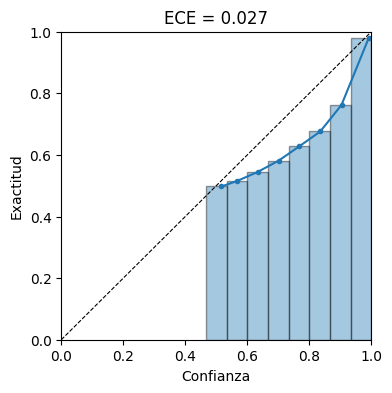

In [6]:
if HAS_TF and MODELS:
    from scipy import stats as sst
    from tensorflow import keras
    from project.calibration import binary_ece, risk_coverage_curve
    from project.models_seg import predict_probs
    from project.postprocess import watershed_from_three_class
    from project.seg_metrics import sartorius_score
    import sys; sys.path.insert(0, str(ROOT / "scripts"))
    from seg_experiments import load_split
    Xt, Yt, tt = load_split("test")
    import json
    from project.models_seg import load_seg_model
    ens = [load_seg_model(str(m), json.loads(Path(str(m).replace(".weights.h5", ".json")).read_text())) for m in MODELS]
    rows, P, G = [], [], []
    for x, y, i in zip(Xt, Yt, tt.id_imagen):
        ps = np.stack([predict_probs(m, x) for m in ens]); pm = ps.mean(0)
        fg = pm[..., 1] + pm[..., 2]; var = ps[..., 1:].sum(-1).var(0)
        mc_mean, mc_var = predict_probs(ens[0], x, mc_samples=20)
        ap = sartorius_score(y, watershed_from_three_class(pm))
        rows.append(dict(id_imagen=i, ap=ap, ece=binary_ece(fg, y > 0), unc_ens=var.mean(),
                         unc_mc=mc_var[..., 1:].sum(-1).mean()))
        sub = np.random.default_rng(0).choice(fg.size, 5000, replace=False)
        P.append(fg.ravel()[sub]); G.append((y > 0).ravel()[sub])
    u = pd.DataFrame(rows)
    print("ECE de píxel (ensamble):", fmt_ci(*bootstrap_ci(u.ece.to_numpy())))
    for c in ("unc_ens", "unc_mc"):
        r = sst.spearmanr(u[c], 1 - u.ap); print(f"Spearman({c}, error) = {r.statistic:.2f} (p = {r.pvalue:.1e})")
    rc = risk_coverage_curve(-u.unc_ens.to_numpy(), u.ap.to_numpy() >= u.ap.median())
    print(f"AURC (predicción selectiva por imagen) = {rc['aurc']:.3f}")
    from project.calibration import plot_reliability
    p = np.concatenate(P); g = np.concatenate(G)
    plot_reliability(np.c_[1 - p, p], g.astype(int), label="U-Net++ ensamble")
else:
    print("Pendiente: requiere TensorFlow y los modelos base entrenados (`make train-seg`).")

## 5. Explicabilidad: Grad-CAM e hipótesis causales verificables

Se aplica Grad-CAM sobre la última capa del codificador de U-Net++, con objetivo = suma de p(borde) en
una región de error, para los 5 peores casos del notebook 02. Cada hipótesis causal se **verifica con
una intervención**. Por ejemplo: «las fusiones en SH-SY5Y se deben a contactos con borde de baja
probabilidad». La prueba consiste en volver a ejecutar el watershed con un `h` menor solo en esas
imágenes y medir si las fusiones bajan sin aumentar las divisiones.

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['image']
Received: inputs=Tensor(shape=(1, 544, 704, 1))
  warnings.warn(msg)


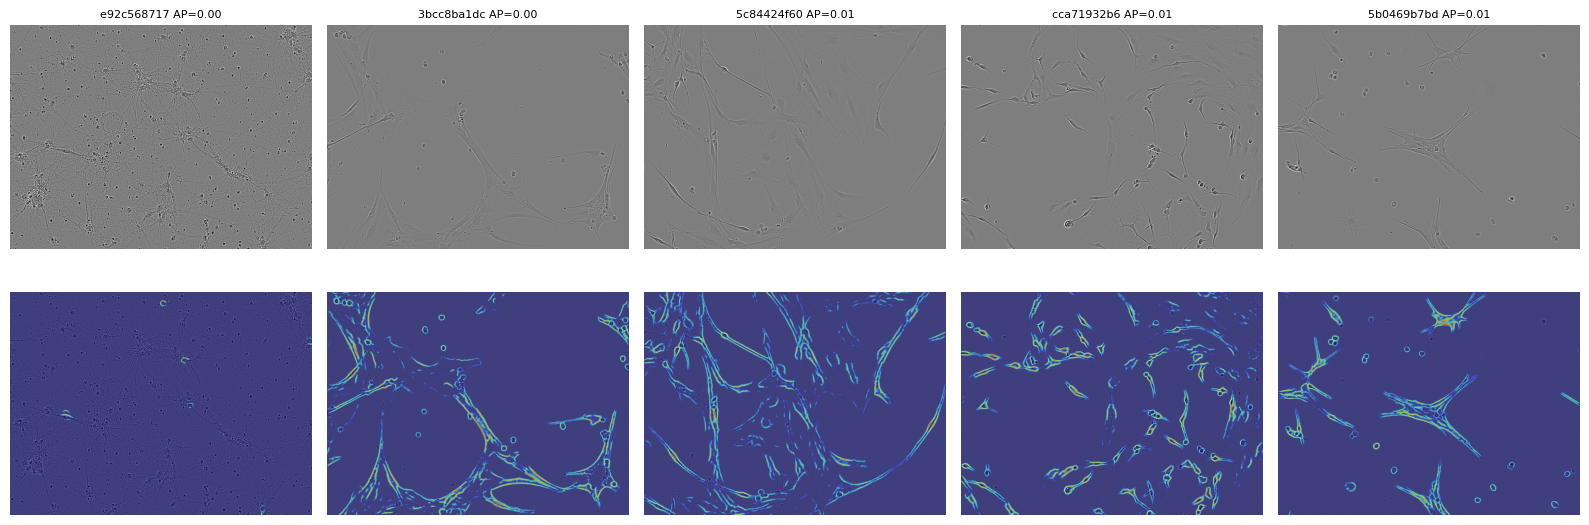

In [7]:
if HAS_TF and MODELS:
    import tensorflow as tf
    m = ens[0]
    layer = [l.name for l in m.layers if l.name.startswith("X") and l.name.endswith("relu1")][-1]
    grad_model = keras.Model(m.inputs, [m.get_layer(layer).output, m.outputs[-1]])
    from project.preprocess_seg import norm_percentile, pad_to_multiple
    fig, ax = plt.subplots(2, 5, figsize=(16, 6))
    worst = u.nsmallest(5, "ap").id_imagen.tolist()
    for j, iid in enumerate(worst):
        k = tt.index[tt.id_imagen == iid][0]
        xx, hw = pad_to_multiple(norm_percentile(Xt[k]), 32)
        with tf.GradientTape() as tape:
            feat, out = grad_model(xx[None, ..., None]); score = tf.reduce_sum(out[..., 2])
        g = tape.gradient(score, feat); w = tf.reduce_mean(g, axis=(1, 2), keepdims=True)
        cam = tf.nn.relu(tf.reduce_sum(w * feat, -1))[0].numpy()
        import cv2
        cam = cv2.resize(cam, (xx.shape[1], xx.shape[0]))[: hw[0], : hw[1]]
        ax[0, j].imshow(Xt[k], cmap="gray"); ax[0, j].set_title(f"{iid[:10]} AP={u.set_index('id_imagen').ap[iid]:.2f}", fontsize=8)
        ax[1, j].imshow(Xt[k], cmap="gray"); ax[1, j].imshow(cam, alpha=0.5, cmap="jet")
    for a in ax.ravel(): a.axis("off")
    plt.tight_layout()
else:
    print("Pendiente: Grad-CAM requiere TensorFlow y el modelo base.")

## 6. Eficiencia y frente de Pareto (AP vs latencia)

Las latencias se miden por imagen en la evaluación. Parámetros, FLOPs y memoria pico de GPU se
registran en los JSON de cada modelo (`models/seg/*.json`), y la energía/CO₂ con `codecarbon`
(`project.efficiency.carbon_tracker`).

                               ap   lat_p50   lat_p95
modelo                                               
Baseline clásico            0.009   325.521   442.075
Cellpose 2.0 (ajustado)     0.236   587.708   710.448
Cellpose 2.0 (generalista)  0.026   436.223   721.046
Hover-Net                   0.145   277.528   307.748
Mask R-CNN (+ Swin)         0.038  1641.893  1798.854
SAM (cero-shot)             0.023  7088.770  7695.101
SAM (prompts de caja)       0.070  1412.147  2043.025
U-Net++ + Watershed         0.161   413.811   473.502


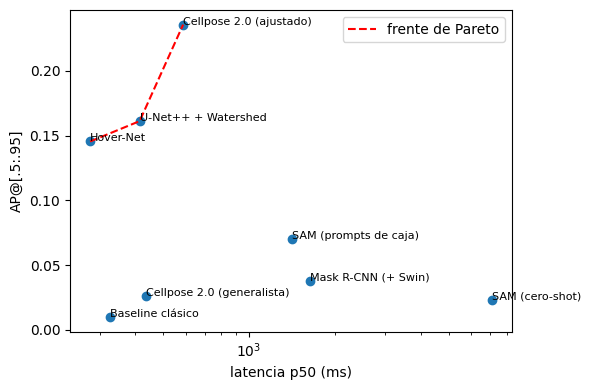

In [8]:
from project.efficiency import pareto_front
if EV.exists():
    ev = pd.read_csv(EV)
    eff = ev.groupby("modelo").agg(ap=("ap", "mean"), lat_p50=("latency_ms", "median"),
                                   lat_p95=("latency_ms", lambda s: s.quantile(0.95)))
    pf = pareto_front(eff.reset_index(), "ap", "lat_p50")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(eff.lat_p50, eff.ap)
    for m, r in eff.iterrows(): ax.annotate(m, (r.lat_p50, r.ap), fontsize=8)
    ax.plot(pf.lat_p50, pf.ap, "r--", label="frente de Pareto"); ax.set_xscale("log")
    ax.set(xlabel="latencia p50 (ms)", ylabel="AP@[.5:.95]"); ax.legend(); plt.tight_layout()
    fig.savefig(FIG / "seg_pareto.png", dpi=120)
    print(eff.round(3))
else:
    print("Pendiente: `seg_eval_test.csv`.")